<a href="https://colab.research.google.com/github/zaosh/FGAI_IA3_Varun_Bramhankar_230953538/blob/main/IA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q datasets transformers accelerate
!pip install -q sentencepiece sacrebleu evaluate
!pip install -q pandas numpy matplotlib scikit-learn
!pip install -q peft bitsandbytes


In [5]:
import os

PROJECT = "/content/FGAI_Assignment_3"

os.makedirs(PROJECT, exist_ok=True)
os.makedirs(f"{PROJECT}/data", exist_ok=True)
os.makedirs(f"{PROJECT}/models", exist_ok=True)
os.makedirs(f"{PROJECT}/results", exist_ok=True)

print("Project directory ready!")

Project directory ready!


In [6]:
os.makedirs(f"{PROJECT}/results/predictions", exist_ok=True)
os.makedirs(f"{PROJECT}/results/evaluation", exist_ok=True)

In [7]:
from google.colab import files

uploaded = files.upload()

Saving hindi_english_parallel.csv to hindi_english_parallel.csv


In [9]:
import os, shutil, pandas as pd

PROJECT = "/content/FGAI_Assignment_3"
os.makedirs(f"{PROJECT}/data", exist_ok=True)

dst = f"{PROJECT}/data/original_dataset.csv"
if not os.path.exists(dst):
    shutil.copy("/content/hindi_english_parallel.csv", dst)
print("File in project folder:", os.path.exists(dst))

df = pd.read_csv(dst)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

File in project folder: True
Shape: (1561841, 2)
Columns: ['hindi', 'english']


,hindi,english
0,अपने अनुप्रयोग को पहुंचनीयता व्यायाम का लाभ दें,Give your application an accessibility workout
1,एक्सेर्साइसर पहुंचनीयता अन्वेषक,Accerciser Accessibility Explorer
2,निचले पटल के लिए डिफोल्ट प्लग-इन खाका,The default plugin layout for the bottom panel
3,ऊपरी पटल के लिए डिफोल्ट प्लग-इन खाका,The default plugin layout for the top panel
4,उन प्लग-इनों की सूची जिन्हें डिफोल्ट रूप से नि...,A list of plugins that are disabled by default


In [10]:
import pandas as pd

COL_EN = "english"
COL_HI = "hindi"

df = pd.read_csv(f"{PROJECT}/data/original_dataset.csv")
print("Raw rows:", len(df))

df = df[[COL_EN, COL_HI]].rename(columns={COL_EN: "en", COL_HI: "hi"})
df = df.dropna()
df["en"] = df["en"].astype(str).str.strip()
df["hi"] = df["hi"].astype(str).str.strip()
df = df[(df.en != "") & (df.hi != "")]
df = df.drop_duplicates().drop_duplicates(subset="en").drop_duplicates(subset="hi")

# keep Hindi side actually in Devanagari, and moderate lengths (keeps training manageable)
df = df[df.hi.str.contains(r"[\u0900-\u097F]", regex=True)]
en_len = df.en.str.split().str.len()
hi_len = df.hi.str.split().str.len()
df = df[en_len.between(4, 25) & hi_len.between(4, 30)]
print("Valid rows after cleaning:", len(df))

assert len(df) >= 4000, "Fewer than 4000 valid rows - tell me the number"
df = df.sample(n=4000, random_state=42).reset_index(drop=True)

train = df.iloc[:3200]
val   = df.iloc[3200:3600]
test  = df.iloc[3600:4000]

train.to_csv(f"{PROJECT}/data/train.csv", index=False)
val.to_csv(f"{PROJECT}/data/validation.csv", index=False)
test.to_csv(f"{PROJECT}/data/test.csv", index=False)
print(len(train), len(val), len(test))
display(test.head())

Raw rows: 1561841
Valid rows after cleaning: 540605
3200 400 400


,en,hi
3600,Still the brave Boer women did not flinch.,फिर भी बहादुर बोअर स्त्रियां झुकी नहीं।
3601,UN Framework convention on climate Change.,जलवायु परिवर्तन पर संयुक्त राष्ट्र का फ्रेमवर्...
3602,But when I heard all this I was rather surprised.,लेकिन ये बात सुनकर मुझे जरा आश्चर्य हुआ।
3603,Energy saving aspects of equipment operations,उपस्कर प्रचालनों के ऊर्जा बचत संबंधी पहलुओं
3604,The former is a simpleton.,शीनू तो बुद्वू है।


In [11]:
import os, json, time, random, shutil, gc
import numpy as np, pandas as pd, torch, sacrebleu
from google.colab import files

PROJECT = "/content/FGAI_Assignment_3"
device = "cuda"

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)

train = pd.read_csv(f"{PROJECT}/data/train.csv")
val   = pd.read_csv(f"{PROJECT}/data/validation.csv")
test  = pd.read_csv(f"{PROJECT}/data/test.csv")
SRC = test["en"].tolist()
REF = test["hi"].tolist()

def evaluate_and_save(name, preds, train_time, infer_time, n_params, arch, adaptation):
    preds = [str(p) for p in preds]
    bleu = sacrebleu.corpus_bleu(preds, [REF]).score
    chrf = sacrebleu.corpus_chrf(preds, [REF]).score
    pd.DataFrame({"source": SRC, "reference": REF, "prediction": preds}).to_csv(
        f"{PROJECT}/results/predictions/{name}.csv", index=False)
    m = dict(model=name, architecture=arch, adaptation=adaptation, params=n_params,
             bleu=round(bleu, 2), chrf=round(chrf, 2),
             train_time_s=None if train_time is None else round(train_time, 1),
             infer_time_s=round(infer_time, 1))
    json.dump(m, open(f"{PROJECT}/results/evaluation/{name}.json", "w"), indent=2)
    print(m)
    return m

def backup():
    shutil.make_archive("/content/backup", "zip", PROJECT)
    files.download("/content/backup.zip")

print("Helpers ready:", len(train), len(val), len(test))

Helpers ready: 3200 400 400


In [12]:
import math, copy
import torch.nn as nn
import sentencepiece as spm
from torch.nn.utils.rnn import pad_sequence

# ---- joint SentencePiece tokenizer trained on the training set only
txt = f"{PROJECT}/models/spm_train.txt"
with open(txt, "w", encoding="utf-8") as f:
    for t in train["en"].tolist() + train["hi"].tolist():
        f.write(t.replace("\n", " ") + "\n")
SP = f"{PROJECT}/models/spm_joint"
spm.SentencePieceTrainer.train(input=txt, model_prefix=SP, vocab_size=5000,
    model_type="unigram", character_coverage=1.0, hard_vocab_limit=False,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file=SP + ".model")
V = sp.get_piece_size()
PAD, BOS, EOS = 0, 2, 3
MAXLEN = 64

def enc(texts, bos=False):
    out = []
    for t in texts:
        ids = sp.encode(t)[:MAXLEN - 2]
        out.append(torch.tensor(([BOS] if bos else []) + ids + [EOS]))
    return out

tr_src, tr_tgt = enc(train.en), enc(train.hi, True)
va_src, va_tgt = enc(val.en),   enc(val.hi, True)

def make_batch(S, T, idx):
    s = pad_sequence([S[i] for i in idx], batch_first=True, padding_value=PAD)
    t = pad_sequence([T[i] for i in idx], batch_first=True, padding_value=PAD)
    return s.to(device), t.to(device)

# ---- model
class PosEnc(nn.Module):
    def __init__(self, d, maxlen=128):
        super().__init__()
        pe = torch.zeros(maxlen, d)
        pos = torch.arange(maxlen).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class TransformerMT(nn.Module):
    def __init__(self, V, d=256, h=4, L=3, ff=512, drop=0.1):
        super().__init__()
        self.d = d
        self.emb = nn.Embedding(V, d, padding_idx=PAD)
        self.pos = PosEnc(d)
        self.tf = nn.Transformer(d, h, L, L, ff, drop, batch_first=True)
        self.out = nn.Linear(d, V, bias=False)
        self.out.weight = self.emb.weight          # tie weights
    def encode(self, src):
        x = self.pos(self.emb(src) * math.sqrt(self.d))
        return self.tf.encoder(x, src_key_padding_mask=(src == PAD))
    def decode(self, tgt, mem, src):
        n = tgt.size(1)
        causal = torch.triu(torch.ones(n, n, dtype=torch.bool, device=tgt.device), 1)
        x = self.pos(self.emb(tgt) * math.sqrt(self.d))
        h = self.tf.decoder(x, mem, tgt_mask=causal,
                            tgt_key_padding_mask=(tgt == PAD),
                            memory_key_padding_mask=(src == PAD))
        return self.out(h)
    def forward(self, src, tgt_in):
        return self.decode(tgt_in, self.encode(src), src)

@torch.no_grad()
def translate_tf(model, texts, bs=64):
    model.eval(); outs = []
    for i in range(0, len(texts), bs):
        batch = enc(texts[i:i + bs])
        src = pad_sequence(batch, batch_first=True, padding_value=PAD).to(device)
        mem = model.encode(src)
        ys = torch.full((src.size(0), 1), BOS, device=device)
        done = torch.zeros(src.size(0), dtype=torch.bool, device=device)
        for _ in range(MAXLEN):
            nxt = model.decode(ys, mem, src)[:, -1].argmax(-1)
            ys = torch.cat([ys, nxt[:, None]], 1)
            done |= nxt == EOS
            if done.all(): break
        for row in ys[:, 1:].tolist():
            if EOS in row: row = row[:row.index(EOS)]
            outs.append(sp.decode(row))
    return outs

print("Vocab size:", V)

Vocab size: 5000


In [13]:
BS, EPOCHS = 64, 40
model = TransformerMT(V).to(device)
n_params = sum(p.numel() for p in model.parameters())
print("Parameters:", n_params)

opt = torch.optim.AdamW(model.parameters(), lr=5e-4, betas=(0.9, 0.98), weight_decay=0.01)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 200))
crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)

@torch.no_grad()
def val_loss():
    model.eval(); tot = 0; n = 0
    for i in range(0, len(va_src), 128):
        idx = list(range(i, min(i + 128, len(va_src))))
        s, t = make_batch(va_src, va_tgt, idx)
        lg = model(s, t[:, :-1])
        tot += crit(lg.reshape(-1, V), t[:, 1:].reshape(-1)).item(); n += 1
    return tot / n

best, best_state = 1e9, None
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    model.train()
    order = torch.randperm(len(tr_src)).tolist()
    for i in range(0, len(order), BS):
        s, t = make_batch(tr_src, tr_tgt, order[i:i + BS])
        lg = model(s, t[:, :-1])
        loss = crit(lg.reshape(-1, V), t[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
    vl = val_loss()
    if vl < best: best, best_state = vl, copy.deepcopy(model.state_dict())
    if ep % 5 == 0 or ep == 1: print(f"epoch {ep}  train_loss {loss.item():.3f}  val_loss {vl:.3f}")
train_time = time.time() - t0
print(f"Training time: {train_time:.1f}s  best val loss {best:.3f}")

model.load_state_dict(best_state)
torch.save(best_state, f"{PROJECT}/models/transformer_best.pt")

torch.cuda.synchronize(); t0 = time.time()
preds = translate_tf(model, SRC)
torch.cuda.synchronize(); infer_time = time.time() - t0

evaluate_and_save("Transformer", preds, train_time, infer_time, n_params,
                  "Encoder-decoder", "Trained from scratch")
for s, r, p in list(zip(SRC, REF, preds))[:3]:
    print("\nEN:", s, "\nREF:", r, "\nPRED:", p)

Parameters: 5234688


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


epoch 1  train_loss 32.006  val_loss 25.519
epoch 5  train_loss 12.811  val_loss 10.978
epoch 10  train_loss 8.286  val_loss 7.205
epoch 15  train_loss 7.038  val_loss 6.588
epoch 20  train_loss 6.540  val_loss 6.499
epoch 25  train_loss 6.051  val_loss 6.457
epoch 30  train_loss 5.583  val_loss 6.497
epoch 35  train_loss 5.184  val_loss 6.586
epoch 40  train_loss 4.954  val_loss 6.644
Training time: 111.5s  best val loss 6.457
{'model': 'Transformer', 'architecture': 'Encoder-decoder', 'adaptation': 'Trained from scratch', 'params': 5234688, 'bleu': 0.23, 'chrf': 5.92, 'train_time_s': 111.5, 'infer_time_s': 3.4}

EN: Still the brave Boer women did not flinch. 
REF: फिर भी बहादुर बोअर स्त्रियां झुकी नहीं। 
PRED: इर्लोर्ल्ल के लिए किया गया।

EN: UN Framework convention on climate Change. 
REF: जलवायु परिवर्तन पर संयुक्त राष्ट्र का फ्रेमवर्क कन्वेंशन, 
PRED: (क)

EN: But when I heard all this I was rather surprised. 
REF: लेकिन ये बात सुनकर मुझे जरा आश्चर्य हुआ। 
PRED: मैं मैं मैं मैं मै

In [14]:
backup()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from transformers import AutoTokenizer, MT5ForConditionalGeneration

name = "google/mt5-small"
tok = AutoTokenizer.from_pretrained(name)
model = MT5ForConditionalGeneration.from_pretrained(name).to(device)
n_params = sum(p.numel() for p in model.parameters())
print("Parameters:", n_params)

PREFIX = "translate English to Hindi: "
def batch_tensors(src, tgt):
    x = tok([PREFIX + s for s in src], max_length=64, truncation=True,
            padding=True, return_tensors="pt").to(device)
    y = tok(text_target=list(tgt), max_length=64, truncation=True,
            padding=True, return_tensors="pt").input_ids
    y[y == tok.pad_token_id] = -100
    return x, y.to(device)

BS, EPOCHS = 16, 8
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.01)
tr_en, tr_hi = train.en.tolist(), train.hi.tolist()
va_en, va_hi = val.en.tolist(), val.hi.tolist()

@torch.no_grad()
def val_loss():
    model.eval(); tot = 0; n = 0
    for i in range(0, len(va_en), 32):
        x, y = batch_tensors(va_en[i:i+32], va_hi[i:i+32])
        tot += model(**x, labels=y).loss.item(); n += 1
    return tot / n

set_seed(42)
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    model.train()
    order = torch.randperm(len(tr_en)).tolist()
    for i in range(0, len(order), BS):
        idx = order[i:i+BS]
        x, y = batch_tensors([tr_en[j] for j in idx], [tr_hi[j] for j in idx])
        loss = model(**x, labels=y).loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    print(f"epoch {ep}  train_loss {loss.item():.3f}  val_loss {val_loss():.3f}")
train_time = time.time() - t0
print(f"Fine-tuning time: {train_time:.1f}s")

@torch.no_grad()
def translate_mt5(texts, bs=32):
    model.eval(); outs = []
    for i in range(0, len(texts), bs):
        x = tok([PREFIX + s for s in texts[i:i+bs]], max_length=64, truncation=True,
                padding=True, return_tensors="pt").to(device)
        g = model.generate(**x, max_new_tokens=64, num_beams=1, do_sample=False)
        outs += tok.batch_decode(g, skip_special_tokens=True)
    return outs

torch.cuda.synchronize(); t0 = time.time()
preds = translate_mt5(SRC)
torch.cuda.synchronize(); infer_time = time.time() - t0

evaluate_and_save("mT5", preds, train_time, infer_time, n_params,
                  "Encoder-decoder", "Full fine-tuning (mt5-small)")
for s, r, p in list(zip(SRC, REF, preds))[:3]:
    print("\nEN:", s, "\nREF:", r, "\nPRED:", p)

del model, opt; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Parameters: 300176768
epoch 1  train_loss 4.161  val_loss 3.172
epoch 2  train_loss 3.586  val_loss 2.938
epoch 3  train_loss 3.132  val_loss 2.837
epoch 4  train_loss 2.805  val_loss 2.770
epoch 5  train_loss 3.053  val_loss 2.736
epoch 6  train_loss 2.691  val_loss 2.724
epoch 7  train_loss 2.707  val_loss 2.726
epoch 8  train_loss 2.610  val_loss 2.729
Fine-tuning time: 710.9s
{'model': 'mT5', 'architecture': 'Encoder-decoder', 'adaptation': 'Full fine-tuning (mt5-small)', 'params': 300176768, 'bleu': 4.31, 'chrf': 21.84, 'train_time_s': 710.9, 'infer_time_s': 13.6}

EN: Still the brave Boer women did not flinch. 
REF: फिर भी बहादुर बोअर स्त्रियां झुकी नहीं। 
PRED: अब ही मजदूर महिला को न लौटने लगी।

EN: UN Framework convention on climate Change. 
REF: जलवायु परिवर्तन पर संयुक्त राष्ट्र का फ्रेमवर्क कन्वेंशन, 
PRED: वर्षा विकास पर राष्ट्रीय स्तर पर एक राष्ट्रीय फ्रेमियम फ्रेममेंट

EN: But when I heard all this I was rather surprised. 
REF: लेकिन ये बात सुनकर मुझे जरा आश्चर्य हुआ। 
PR

In [16]:
backup()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from huggingface_hub import login
login()

In [18]:
from transformers import AutoTokenizer, AutoModelForCausalLM

shots = train[train.en.str.split().str.len().between(6, 12)].head(3)
def build_prompt(src):
    p = "Translate English to Hindi. Output only the Hindi translation.\n\n"
    for _, r in shots.iterrows():
        p += f"English: {r.en}\nHindi: {r.hi}\n\n"
    return p + f"English: {src}\nHindi:"

def clean_out(t):
    t = t.strip().split("\n")[0].strip()
    for pre in ["Hindi:", "हिंदी:"]:
        if t.startswith(pre): t = t[len(pre):].strip()
    return t

def generate_llm(model, tok, sources, temperature=0.0, bs=16, max_new=160):
    outs = []
    for i in range(0, len(sources), bs):
        prompts = [tok.apply_chat_template([{"role": "user", "content": build_prompt(s)}],
                   add_generation_prompt=True, tokenize=False) for s in sources[i:i+bs]]
        x = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        kw = dict(max_new_tokens=max_new, pad_token_id=tok.pad_token_id)
        if temperature > 0:
            kw.update(do_sample=True, temperature=temperature, top_p=1.0, top_k=0)
        else:
            kw.update(do_sample=False)
        with torch.no_grad():
            g = model.generate(**x, **kw)
        outs += [clean_out(t) for t in tok.batch_decode(g[:, x.input_ids.shape[1]:], skip_special_tokens=True)]
    return outs

def run_llm_experiment(model_id, label, dtype, temps=(0.3, 0.7, 1.0), n_temp=100):
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    try:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype).to(device)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype).to(device)
    model.eval()
    n_params = sum(p.numel() for p in model.parameters())
    print(label, "parameters:", n_params)

    # main result: greedy on the full test set
    set_seed(42)
    torch.cuda.synchronize(); t0 = time.time()
    preds = generate_llm(model, tok, SRC)
    torch.cuda.synchronize(); infer_time = time.time() - t0
    evaluate_and_save(label, preds, None, infer_time, n_params,
                      "Decoder-only", "Few-shot prompting (3 examples), no fine-tuning")

    # temperature analysis on first n_temp test sentences
    rows = [dict(temperature=0.0, bleu=sacrebleu.corpus_bleu(preds[:n_temp], [REF[:n_temp]]).score,
                 chrf=sacrebleu.corpus_chrf(preds[:n_temp], [REF[:n_temp]]).score)]
    for T in temps:
        set_seed(42)
        p = generate_llm(model, tok, SRC[:n_temp], temperature=T)
        rows.append(dict(temperature=T, bleu=sacrebleu.corpus_bleu(p, [REF[:n_temp]]).score,
                         chrf=sacrebleu.corpus_chrf(p, [REF[:n_temp]]).score))
        pd.DataFrame({"source": SRC[:n_temp], "reference": REF[:n_temp], "prediction": p}).to_csv(
            f"{PROJECT}/results/predictions/{label}_temp{T}.csv", index=False)
    tdf = pd.DataFrame(rows).round(2)
    tdf.to_csv(f"{PROJECT}/results/evaluation/temperature_{label}.csv", index=False)
    display(tdf)

    for s, r, p in list(zip(SRC, REF, preds))[:3]:
        print("\nEN:", s, "\nREF:", r, "\nPRED:", p)
    del model; gc.collect(); torch.cuda.empty_cache()

In [19]:
run_llm_experiment("google/gemma-3-1b-it", "Gemma", torch.float32)

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (3 outputs left out)

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Gemma parameters: 999885952
{'model': 'Gemma', 'architecture': 'Decoder-only', 'adaptation': 'Few-shot prompting (3 examples), no fine-tuning', 'params': 999885952, 'bleu': 9.36, 'chrf': 35.26, 'train_time_s': None, 'infer_time_s': 83.4}


,temperature,bleu,chrf
0,0.0,10.95,37.66
1,0.3,12.25,37.82
2,0.7,12.21,37.39
3,1.0,11.39,35.02



EN: Still the brave Boer women did not flinch. 
REF: फिर भी बहादुर बोअर स्त्रियां झुकी नहीं। 
PRED: अब Boer महिलाओं ने हिम्मत नहीं हारी।

EN: UN Framework convention on climate Change. 
REF: जलवायु परिवर्तन पर संयुक्त राष्ट्र का फ्रेमवर्क कन्वेंशन, 
PRED: अंतर्राष्ट्रीय जलवायु परिवर्तन फ्रेमवर्क कन्वेंशन

EN: But when I heard all this I was rather surprised. 
REF: लेकिन ये बात सुनकर मुझे जरा आश्चर्य हुआ। 
PRED: लेकिन जब मैं सब कुछ सुनता हूँ तो मैं थोड़ा आश्चर्यचकित हुआ।


In [20]:
backup()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
run_llm_experiment("unsloth/Llama-3.2-1B-Instruct", "LLaMA", torch.float16)

config.json:   0%|          | 0.00/894 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

... (7 outputs left out)

{'model': 'LLaMA', 'architecture': 'Decoder-only', 'adaptation': 'Few-shot prompting (3 examples), no fine-tuning', 'params': 1235814400, 'bleu': 2.42, 'chrf': 11.67, 'train_time_s': None, 'infer_time_s': 95.7}


[transformers] Both `max_new_tokens` (=160) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https:/

,temperature,bleu,chrf
0,0.0,1.05,8.08
1,0.3,1.33,10.62
2,0.7,1.50,10.08
3,1.0,0.39,7.56



EN: Still the brave Boer women did not flinch. 
REF: फिर भी बहादुर बोअर स्त्रियां झुकी नहीं। 
PRED: बढ़वा

EN: UN Framework convention on climate Change. 
REF: जलवायु परिवर्तन पर संयुक्त राष्ट्र का फ्रेमवर्क कन्वेंशन, 
PRED: UN Framework convention on climate Change

EN: But when I heard all this I was rather surprised. 
REF: लेकिन ये बात सुनकर मुझे जरा आश्चर्य हुआ। 
PRED: बहुत ही अच्छा प्रश्न।


In [22]:
backup()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,model,architecture,adaptation,params_M,bleu,chrf,train_time_s,infer_time_s,infer_ms_per_sentence
0,Transformer,Encoder-decoder,Trained from scratch,5.2,0.23,5.92,111.5,3.4,8.5
1,mT5,Encoder-decoder,Full fine-tuning (mt5-small),300.2,4.31,21.84,710.9,13.6,34.0
2,LLaMA,Decoder-only,"Few-shot prompting (3 examples), no fine-tuning",1235.8,2.42,11.67,NaN,95.7,239.3
3,Gemma,Decoder-only,"Few-shot prompting (3 examples), no fine-tuning",999.9,9.36,35.26,NaN,83.4,208.5


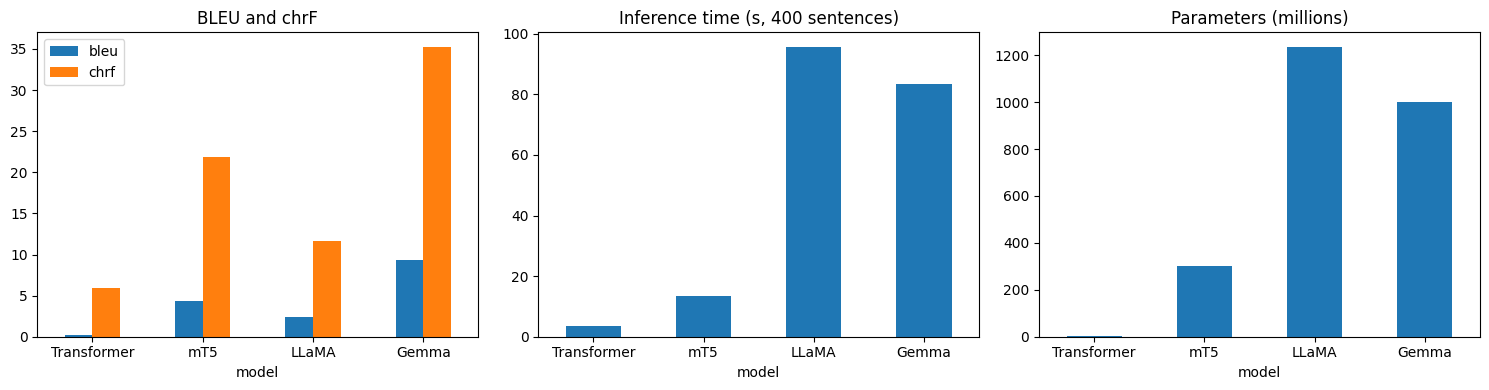

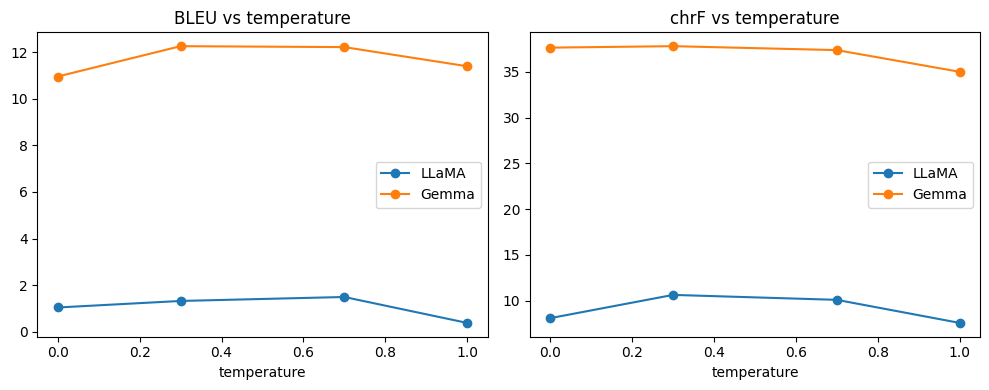

In [23]:
import matplotlib.pyplot as plt

order = ["Transformer", "mT5", "LLaMA", "Gemma"]
res = pd.DataFrame([json.load(open(f"{PROJECT}/results/evaluation/{n}.json")) for n in order])
res["params_M"] = (res.params / 1e6).round(1)
res["infer_ms_per_sentence"] = (res.infer_time_s / len(SRC) * 1000).round(1)
table = res[["model", "architecture", "adaptation", "params_M", "bleu", "chrf",
             "train_time_s", "infer_time_s", "infer_ms_per_sentence"]]
table.to_csv(f"{PROJECT}/results/evaluation/results_table.csv", index=False)
display(table)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
res.plot.bar(x="model", y=["bleu", "chrf"], ax=ax[0], rot=0, title="BLEU and chrF")
res.plot.bar(x="model", y="infer_time_s", ax=ax[1], rot=0, legend=False, title="Inference time (s, 400 sentences)")
res.plot.bar(x="model", y="params_M", ax=ax[2], rot=0, legend=False, title="Parameters (millions)")
plt.tight_layout(); plt.savefig(f"{PROJECT}/results/evaluation/comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for lab in ["LLaMA", "Gemma"]:
    t = pd.read_csv(f"{PROJECT}/results/evaluation/temperature_{lab}.csv")
    ax[0].plot(t.temperature, t.bleu, marker="o", label=lab)
    ax[1].plot(t.temperature, t.chrf, marker="o", label=lab)
ax[0].set_title("BLEU vs temperature"); ax[1].set_title("chrF vs temperature")
for a in ax: a.set_xlabel("temperature"); a.legend()
plt.tight_layout(); plt.savefig(f"{PROJECT}/results/evaluation/temperature.png", dpi=150); plt.show()

In [24]:
backup()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
names = ["Transformer", "mT5", "LLaMA", "Gemma"]
P = {n: pd.read_csv(f"{PROJECT}/results/predictions/{n}.csv") for n in names}
base = P["Transformer"][["source", "reference"]].copy()
for n in names:
    base[n] = P[n]["prediction"].fillna("").astype(str)

# hallucination proxy: output length far from reference length, or empty
ref_len = base.reference.str.split().str.len()
for n in names:
    ratio = base[n].str.split().str.len() / ref_len
    print(f"{n:12s} >2x ref length: {(ratio > 2).sum():3d} | <0.5x: {(ratio < 0.5).sum():3d} | empty: {(base[n].str.strip() == '').sum()}")

# sentences touching gender / religion / violence / authority (for bias & sensitivity discussion)
kw = r"\b(he|she|his|her|man|woman|men|women|girl|boy|muslim|hindu|christian|caste|religio\w*|god|temple|mosque|church|war|kill\w*|terror\w*|rape|police|minister|doctor|nurse)\b"
sub = base[base.source.str.contains(kw, case=False, regex=True)]
print("\nSensitive/bias-related sentences in test set:", len(sub))
sub.to_csv(f"{PROJECT}/results/predictions/sensitive_subset.csv", index=False)
base.sample(15, random_state=1).to_csv(f"{PROJECT}/results/predictions/sample_translations.csv", index=False)
display(sub[["source", "reference"] + names].head(15))

Transformer  >2x ref length: 118 | <0.5x: 108 | empty: 0
mT5          >2x ref length:  16 | <0.5x:  13 | empty: 0
LLaMA        >2x ref length:  26 | <0.5x:  91 | empty: 0
Gemma        >2x ref length:   6 | <0.5x:  10 | empty: 0

Sensitive/bias-related sentences in test set: 53


/tmp/ipykernel_1700/1672201787.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  sub = base[base.source.str.contains(kw, case=False, regex=True)]


,source,reference,Transformer,mT5,LLaMA,Gemma
0,Still the brave Boer women did not flinch.,फिर भी बहादुर बोअर स्त्रियां झुकी नहीं।,इर्लोर्ल्ल के लिए किया गया।,अब ही मजदूर महिला को न लौटने लगी।,बढ़वा,अब Boer महिलाओं ने हिम्मत नहीं हारी।
7,When the Govt. got hold of this material they ...,तेजा सिंह जब सरकार को यह सामग्री मिली तो उसने ...,इस के साथ की शंद की छा की छ की छ की छ की छ की...,"जब सरकार ने इस प्रकार का प्रयोग किया, उन्होंने...",Let us dream through the prism of posterity.,सरकार ने इस सामग्री पर नियंत्रण तब हासिल किया ...
20,He is to be dragged out of the rest.,महाराजा को बाकी के जागीरदारों से खींचकर अलग कर...,इस तरह का का का का का का का का का का का का का ...,वह पूरे तक ही न हटाना है।,Let us dream through the prism of posterity.,वह बाकी सब से बाहर निकाला जाएगा।
32,"St. Francis Church, Kochi","सेंट फ्रांसिस चर्च, कोचीन","बान की एक गा,","नर्मदा स्कूल, नागालैंड","St. Francis Church, Kochi","सेंट फ्रान्सिस चर्च, कोची"
41,So he will be offered food as a ritual.,इसलिए उसे विधिपूर्वक खाना दिया जाता है।,एक ढ़ा गया।,तो वह भोजन को एक प्रकार से उपयोग किया जाएगा।,बग #% 1 [Merged with:% 2] (% 3):% 4,"इसलिए, वह एक अनुष्ठान के रूप में भोजन के लिए प..."
47,We walked into the offices of the municipal co...,"हम लोग नगरपालिका, पुलिस",डििििििििििििििििििििििििििििििििििि के लिए डि...,हमने लोक संस्था के कार्यालयों के रूमों में लौट...,मunicipal corporation office,हम नगरपालिका कार्यालय और पुलिस के कार्यालय में...
50,"Of course, when he composed this work at a rip...",निस्संदेह अपनी वृद्धावस्था में उन्होंने जब इस ...,इ इ इा ने इसा की नीनीनीनीनीनीनीनीनीनीनीनीनीनीन...,"और जब उसने यह कार्य किया, तो वह अब भी वह अब भी...",बग #% 1 [Merged with:% 2] (% 3):% 4,"ज़रूर, यहाँ अनुवाद है:"
53,I would put it this way: he attained martyrdom.,मैं कहता हूं उसे शहादत नसीब हुई।,मैं इस ूंगाूंगाूंगाूंगाूंगाूंगाूंगाूंगाूंगाूंग...,मैं इस तरह से इस तरह यह किया।,मartyrdom,मैं इसे इस तरह कहूँगा: वह मृत्यु के क्षेत्र मे...
60,"No, for I haven 't yet won his heart.","नहीं, मैं अभी तक उनके हृदय में अपनी जगह नहीं ब...","मैं की डा, की भी, की की की कर दिया।",मैं अपने दिल को न ही नहीं किया।,Let us dream through the prism of posterity.,"नहीं, मैं अभी उसका दिल नहीं जीत पाया हूँ।"
77,He had been much impressed by Edward Maitland ...,वे एडवर्ड मेटलैंड कृत दि परफेक्ट वे से बहुत अध...,इ खिलर्दर्दन की इ का एक झर्दन की झर्दन की झर्द...,वह ईंट मैनटन के लिए बहुत ही आभास थी।,He had been much impressed by Edward Maitland ...,उसने बहुत प्रभावित होकर एडवर्ड मैईटली के ‘द पर...


In [26]:
backup()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
display(shots[["en", "hi"]])

,en,hi
3,Let us dream through the prism of posterity.,"आइए, हम भावी पीढ़ियों की आंखों से सपना देखें।"
5,Bug #% 1 [Merged with:% 2] (% 3):% 4,बग #% 1 [% 2 के साथ मिला दिया] (% 3):% 4bug #n...
7,Let 's look at the development side.,अब विकास के क्षेत्र की तरफ देखें.
